<a href="https://colab.research.google.com/github/Dalton115/MAT-422/blob/main/HW3_5_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW 3.5 & 3.6

* Used Gemini as a study aid and coding partner to clarify multivariate calculus definitions, debug python code, and format LaTex formulas.
__________________________________________________________________

1. K-Means Clustering- (3.5)
2. Support Vector Machines (SVM)- (3.6)

_________________________________________________________________

# K-Means Clustering 3.5

Key Concepts (summarized then demonstated with python examples):

* K-Means Clustering is an unsupervised learning algorithm used to group unlabeled data into a chosen number (k) of distinct, non-overlapping clusters based on feature simularity.

* K-means minimizes the within-cluster variance (squared Euclidean distance of points from their cluster centroid):$$\text{WCSS}_i = \sum_{x \in S_i} \Vert{}x - \mu(S_i)\Vert{}^2$$where the cluster centroid $\mu(S_i)$ is defined as the arithmetic mean of all points in $S_i$:$$\mu(S_i) = \frac{1}{\vert{}S_i\vert{}} \sum_{x \in S_i} x$$The global optimization problem is:$$\arg\min_{S} \sum_{i=1}^{k} \text{WCSS}_i = \arg\min_{S} \sum_{i=1}^{k} \sum_{x \in S_i} \Vert{}x - \mu(S_i)\Vert{}^2$$

The algorithm steps consist of


* Initialization: Select $k$ predefined cluster centers randomly from $\mathbb{R}^d$ or from the data points.

* Assignment Step: Assign each observation $x_j$ to its nearest cluster center based on Euclidean distance:$$S_i^{(t)} = \left\{ x_j : \Vert{}x_j - \mu_i^{(t)}\Vert{}^2 \le \Vert{}x_j - \mu_l^{(t)}\Vert{}^2 \quad \forall \, 1 \le l \le k \right\}
$$Update Step: Recalculate the centroid (mean vector) for each cluster:$$\mu_i^{(t+1)} = \frac{1}{\vert{}S_i^{(t)}\vert{}} \sum_{x \in S_i^{(t)}} x$$Convergence: Repeat steps 2 and 3 until cluster assignments no longer change between iterations.



An important aspect of K-means is Monotonic convergence, meaning it converges to a local optimum. It is proven through the following steps:

* Show that the objective function: $F(S, \mu) = \sum_{i=1}^{k} \sum_{x \in S_i} \Vert{}x - \mu_i\Vert{}^2$
 monotonically decreases at each step:

 * Reassignment Step: Fixing centroids $\mu$, reassigning points $x$ to their nearest centroid guarantees that $\Vert{}x - \mu_i\Vert{}^2$ decreases or stays equal for every point $x$. Thus, $F(S, \mu)$ decreases.

 * Recomputation Step: Fixing cluster assignments $S_i$, we find the optimal vector $v = (v_1, \dots, v_d)^T$ minimizing WCSS for cluster $S_i$:$$\text{WCSS}_i(v) = \sum_{x \in S_i} \Vert{}v - x\Vert{}^2 = \sum_{x \in S_i} \sum_{j=1}^{d} (v_j - x_j)^2$$Taking the partial derivative with respect to the $m$-th component $v_m$:$$\frac{\partial \text{WCSS}_i(v)}{\partial v_m} = \sum_{x \in S_i} 2(v_m - x_m) = 0$$Solving for $v_m$:$$2\vert{}S_i\vert{} v_m - 2 \sum_{x \in S_i} x_m = 0 \implies v_m = \frac{1}{\vert{}S_i\vert{}} \sum_{x \in S_i} x_m$$In vector form:$$v = \frac{1}{\vert{}S_i\vert{}} \sum_{x \in S_i} x$$Since the partial derivative yields the mean vector, replacing old centroids with cluster means strictly minimizes WCSS for each cluster. Because $F(S, \mu)$ is bounded below by 0 and monotonically non-increasing at each step, K-means is guaranteed to converge in a finite number of steps.

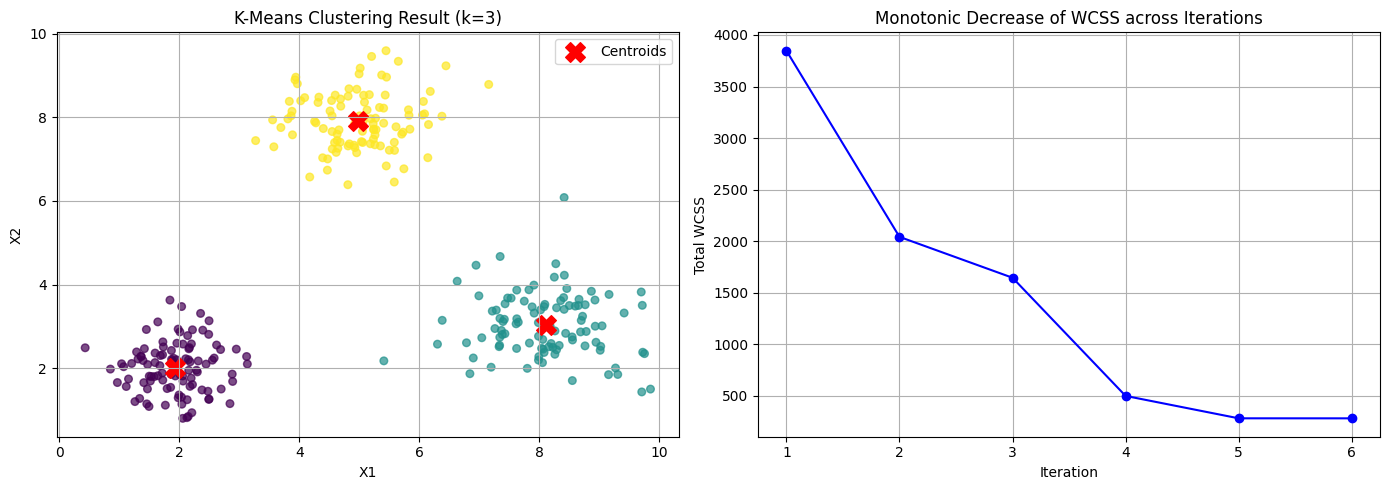

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Set seed for reproducibility
np.random.seed(42)


class CustomKMeans:

    def __init__(self, k=3, max_iters=100, tol=1e-5):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.centroids = None
        self.wcss_history = []

    def fit(self, X):
        n_samples, n_features = X.shape

        # Step 1: Random centroid initialization
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices]

        for iteration in range(self.max_iters):
            # Step 2: Assignment step (nearest centroid)
            distances = np.linalg.norm(
                X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2
            )
            labels = np.argmin(distances, axis=1)

            # Calculate total WCSS for convergence check
            current_wcss = 0
            for i in range(self.k):
                cluster_points = X[labels == i]
                if len(cluster_points) > 0:
                    current_wcss += np.sum(
                        (cluster_points - self.centroids[i]) ** 2
                    )
            self.wcss_history.append(current_wcss)

            # Step 3: Recomputation step (calculating means)
            new_centroids = np.zeros_like(self.centroids)
            for i in range(self.k):
                cluster_points = X[labels == i]
                if len(cluster_points) > 0:
                    new_centroids[i] = np.mean(cluster_points, axis=0)
                else:
                    new_centroids[i] = self.centroids[i]

            # Step 4: Check convergence
            centroid_shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if centroid_shift < self.tol:
                break

        return labels


# Generate synthetic multi-cluster dataset
c1 = np.random.normal(loc=[2, 2], scale=0.6, size=(100, 2))
c2 = np.random.normal(loc=[8, 3], scale=0.8, size=(100, 2))
c3 = np.random.normal(loc=[5, 8], scale=0.7, size=(100, 2))
X_kmeans = np.vstack([c1, c2, c3])

# Fit Custom K-Means
kmeans = CustomKMeans(k=3)
labels = kmeans.fit(X_kmeans)

# Plotting Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Clusters & Centroids
axes[0].scatter(
    X_kmeans[:, 0], X_kmeans[:, 1], c=labels, cmap="viridis", alpha=0.7, s=30
)
axes[0].scatter(
    kmeans.centroids[:, 0],
    kmeans.centroids[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids",
)
axes[0].set_title("K-Means Clustering Result (k=3)")
axes[0].set_xlabel("X1")
axes[0].set_ylabel("X2")
axes[0].legend()
axes[0].grid(True)

# Plot Monotonic Decrease of WCSS
axes[1].plot(
    range(1, len(kmeans.wcss_history) + 1),
    kmeans.wcss_history,
    marker="o",
    color="b",
)
axes[1].set_title("Monotonic Decrease of WCSS across Iterations")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Total WCSS")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Above shows K-means clustering done with k = 3. It is easy to see visually the algorithm was succesful at separating the centroids into 3 distinct, non overlapping clusters. Additionally, the graph on the right visualizes the monotonic convergence over iterations, showing it clearly converges to a local optimum.

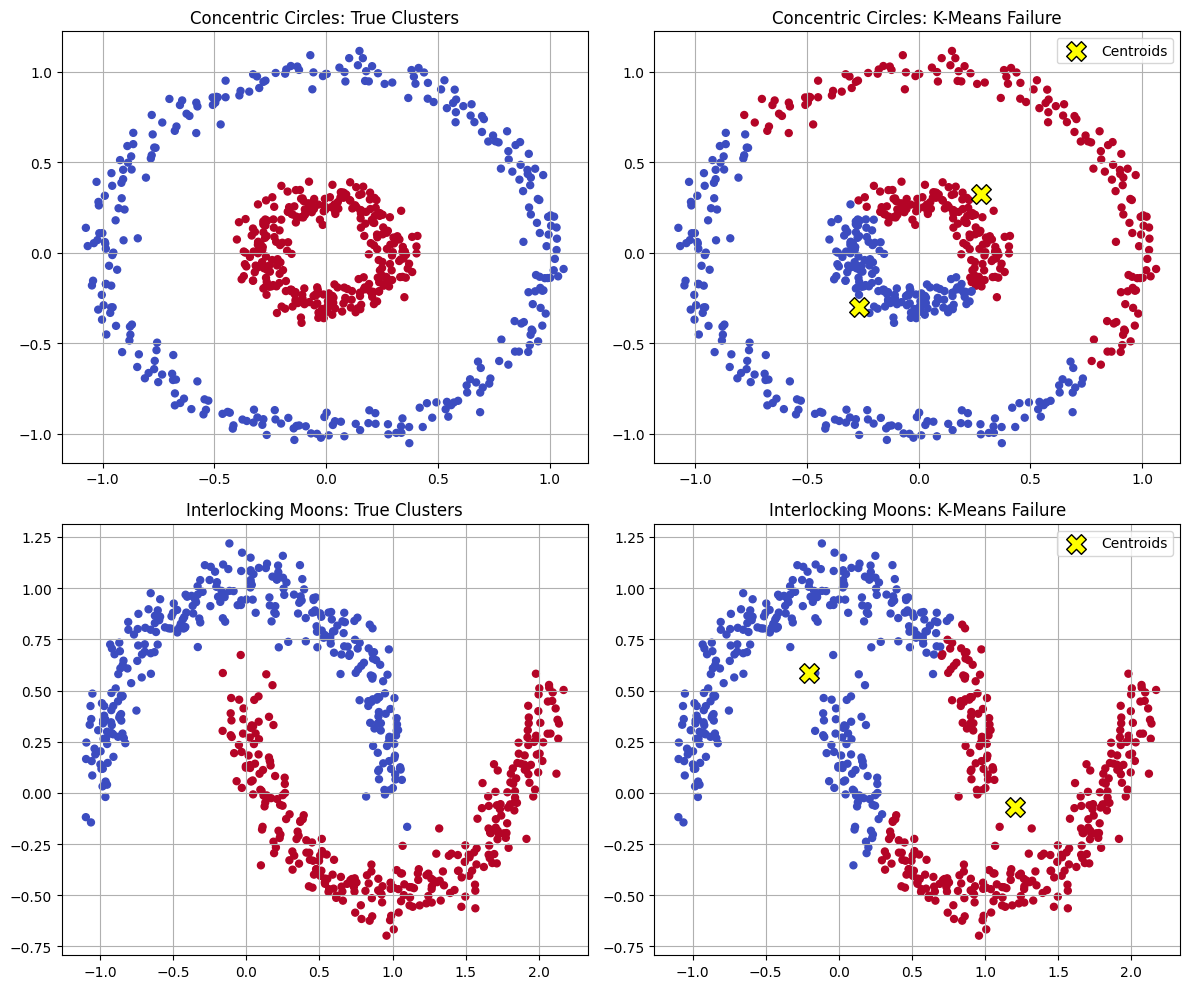

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_circles, make_moons

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate Non-Globular Datasets
# Case A: Concentric Circles
X_circles, y_circles = make_circles(
    n_samples=600, factor=0.3, noise=0.05, random_state=42
)

# Case B: Interlocking Moons
X_moons, y_moons = make_moons(n_samples=600, noise=0.08, random_state=42)

# 2. Apply K-Means Clustering (k=2)
kmeans_circles = KMeans(n_clusters=2, random_state=42, n_init=10).fit(
    X_circles
)
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_moons)

# 3. Visualization
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Concentric Circles - Ground Truth
axes[0, 0].scatter(
    X_circles[:, 0], X_circles[:, 1], c=y_circles, cmap="coolwarm", s=25
)
axes[0, 0].set_title("Concentric Circles: True Clusters")
axes[0, 0].grid(True)

# Concentric Circles - K-Means Failure
axes[0, 1].scatter(
    X_circles[:, 0],
    X_circles[:, 1],
    c=kmeans_circles.labels_,
    cmap="coolwarm",
    s=25,
)
axes[0, 1].scatter(
    kmeans_circles.cluster_centers_[:, 0],
    kmeans_circles.cluster_centers_[:, 1],
    c="yellow",
    marker="X",
    s=200,
    edgecolor="black",
    label="Centroids",
)
axes[0, 1].set_title("Concentric Circles: K-Means Failure")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Interlocking Moons - Ground Truth
axes[1, 0].scatter(
    X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="coolwarm", s=25
)
axes[1, 0].set_title("Interlocking Moons: True Clusters")
axes[1, 0].grid(True)

# Interlocking Moons - K-Means Failure
axes[1, 1].scatter(
    X_moons[:, 0], X_moons[:, 1], c=kmeans_moons.labels_, cmap="coolwarm", s=25
)
axes[1, 1].scatter(
    kmeans_moons.cluster_centers_[:, 0],
    kmeans_moons.cluster_centers_[:, 1],
    c="yellow",
    marker="X",
    s=200,
    edgecolor="black",
    label="Centroids",
)
axes[1, 1].set_title("Interlocking Moons: K-Means Failure")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

This is just a few examples where K-means does not work, giving us some insight into how K-means works. Since it works by minimizing variance based strictly on Euclidean distances to a point mean $\mu$, it assumes clusters are spherical and linearly separable, and fails for sets of points not spherically shaped or linearly separable.

The examples above show K-means failure for concentric rings (since K-means clusters can't overlap), and for intertwining U shapes (because the groupings are spherical).

# Support Vector Machines (SVM) 3.6

Key Concepts (summarized then demonstrated with python examples):

* An SVM is a supervised learning algorithm used for binary classification. Given dataset $\{(x_1, y_1), (x_2, y_2), \dots, (x_n, y_n)\}$, where $x_i \in \mathbb{R}^p$ and $y_i \in \{-1, +1\}$, SVM finds an optimal separating hyperplane that maximizes the margin between the two classes.

* A hyperplane is represented as:$$w^T x - b = 0$$where $w \in \mathbb{R}^p$ is the weight vector normal to the hyperplane, and $b \in \mathbb{R}$ is the bias offset.
* For linearly separable data, two parallel bounding hyperplanes define the margin boundaries:$$w^T x - b = 1 \quad \text{and} \quad w^T x - b = -1$$Data points where $y_i = 1$ must satisfy $w^T x_i - b \ge 1$.Data points where $y_i = -1$ must satisfy $w^T x_i - b \le -1$.
* Combining these gives the functional constraint:$$y_i (w^T x_i - b) \ge 1, \quad \forall i = 1, \dots, n$$The physical distance between the two margin boundaries is $\frac{2}{\Vert{}w\Vert{}}$. Maximizing this margin is equivalent to minimizing $\frac{1}{2}\Vert{}w\Vert{}^2$ or $\Vert{}w\Vert{}^2$.

* For non-perfectly separable data, soft-margin optimization introduces a trade-off parameter $\lambda$ using regularized Hinge Loss:$$\min_{w, b} \left\{ \underbrace{\lambda \Vert{}w\Vert{}^2}_{\text{Regularizer}} + \frac{1}{n} \sum_{i=1}^{n} \underbrace{\max\left(0, 1 - y_i(w^T x_i - b)\right)}_{\text{Hinge Loss Error Term}} \right\}
$$Regularization parameter $\lambda$: Controls model simplicity (larger margin vs. classification accuracy).
* Hinge Loss: Penalizes points that fall inside the margin boundary or on the incorrect side of the hyperplane.
* Using Stochastic Gradient Descent (SGD), we pick a single random sample $(x_i, y_i)$ at step $t$ with learning rate $\beta$:
* Margin Condition Check: $1 - y_i(w^T x_i - b) > 0$ (Point violates margin or is misclassified).
* Bias Update Rule:$$\text{New } b = \text{Old } b - \beta \cdot \begin{cases} y_i & \text{if } 1 - y_i(w^T x_i - b) > 0 \\ 0 & \text{otherwise} \end{cases}$$Weight Update Rule:$$\text{New } w = \text{Old } w - \beta \cdot \begin{cases} 2\lambda w - \frac{1}{n} y_i x_i & \text{if } 1 - y_i(w^T x_i - b) > 0 \\ 2\lambda w & \text{otherwise} \end{cases}$$

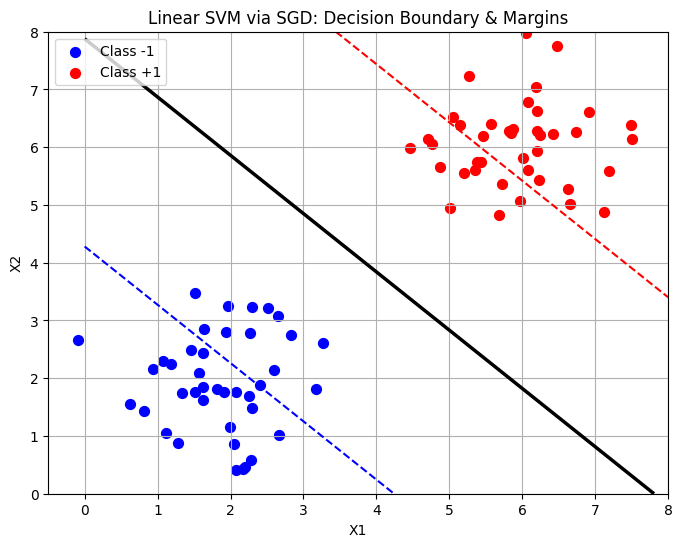

In [3]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)


class LinearSVM_SGD:

    def __init__(self, lambda_param=0.01, learning_rate=0.001, epochs=1000):
        self.lambda_param = lambda_param
        self.beta = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0

        for epoch in range(self.epochs):
            # Stochastic shuffle
            indices = np.arange(n_samples)
            np.random.shuffle(indices)

            for i in indices:
                x_i = X[i]
                y_i = y[i]

                # Check margin condition: 1 - y_i(w^T x_i - b) > 0
                condition = 1 - y_i * (np.dot(self.w, x_i) - self.b) > 0

                if condition:
                    # Update parameters per Eq 3.6.1
                    self.b = self.b - self.beta * y_i
                    self.w = self.w - self.beta * (
                        2 * self.lambda_param * self.w - (1 / n_samples) * y_i * x_i
                    )
                else:
                    self.w = self.w - self.beta * (
                        2 * self.lambda_param * self.w
                    )

    def predict(self, X):
        return np.sign(np.dot(X, self.w) - self.b)


# Generate linearly separable synthetic classification dataset
class_1 = np.random.normal(loc=[2, 2], scale=0.8, size=(40, 2))
class_2 = np.random.normal(loc=[6, 6], scale=0.8, size=(40, 2))

X_svm = np.vstack([class_1, class_2])
y_svm = np.hstack([-np.ones(40), np.ones(40)])

# Fit Linear SVM via SGD
svm = LinearSVM_SGD(lambda_param=0.01, learning_rate=0.01, epochs=2000)
svm.fit(X_svm, y_svm)

# Plot Decision Hyperplane and Margins
plt.figure(figsize=(8, 6))

# Plot data points
plt.scatter(
    X_svm[y_svm == -1][:, 0],
    X_svm[y_svm == -1][:, 1],
    color="blue",
    label="Class -1",
    s=50,
)
plt.scatter(
    X_svm[y_svm == 1][:, 0],
    X_svm[y_svm == 1][:, 1],
    color="red",
    label="Class +1",
    s=50,
)

# Meshgrid for hyperplane plotting
x1_vals = np.linspace(0, 8, 200)
x2_vals = np.linspace(0, 8, 200)
X1, X2 = np.meshgrid(x1_vals, x2_vals)
grid_points = np.c_[X1.ravel(), X2.ravel()]

# Calculate hyperplane values: w^T x - b
Z = np.dot(grid_points, svm.w) - svm.b
Z = Z.reshape(X1.shape)

# Draw decision boundary (Z=0) and margins (Z=1, Z=-1)
plt.contour(
    X1,
    X2,
    Z,
    levels=[-1, 0, 1],
    colors=["blue", "black", "red"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.5, 1.5],
)

plt.title("Linear SVM via SGD: Decision Boundary & Margins")
plt.xlabel("X1")
plt.ylabel("X2")
plt.legend()
plt.grid(True)
plt.show()

The above example shows the result of SVM, where the black line (decision hyperplane) succesfully serparates the two classes. The red and blue dashed lines are the margin boundaries.

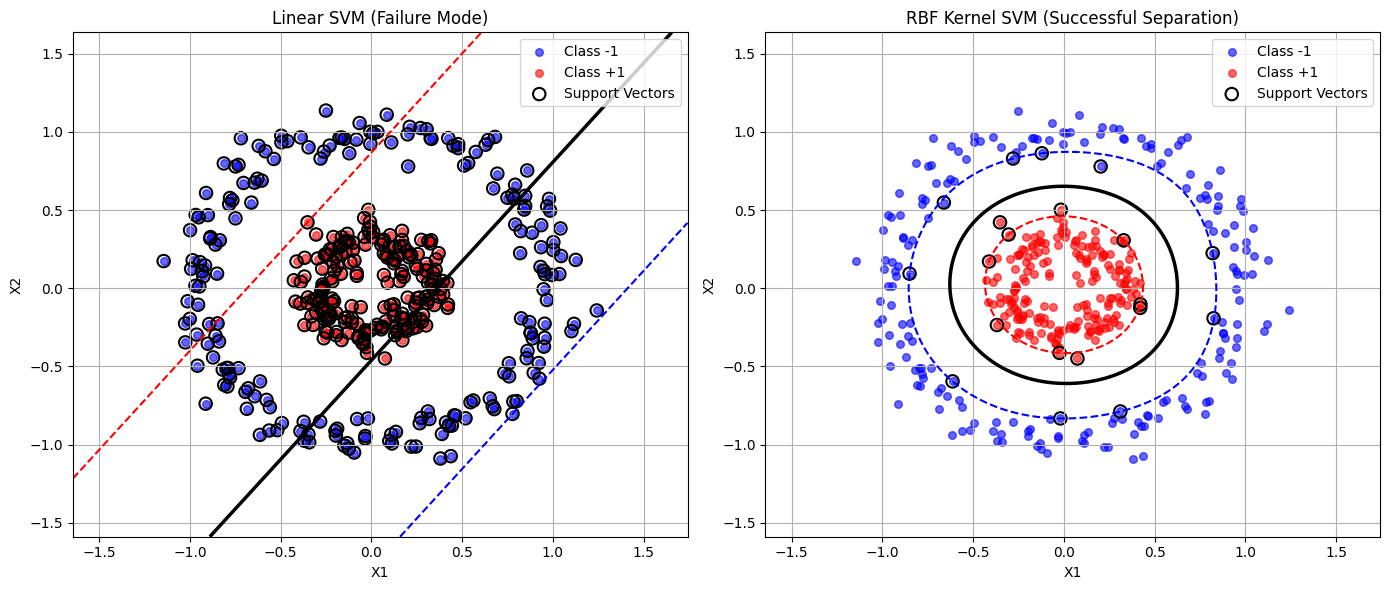

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.svm import SVC

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate Non-Linearly Separable Data (Concentric Circles)
X_svm_nl, y_svm_nl = make_circles(
    n_samples=400, factor=0.3, noise=0.08, random_state=42
)
# Convert target labels from {0, 1} to {-1, +1}
y_svm_nl = np.where(y_svm_nl == 0, -1, 1)

# 2. Train Models
# Model A: Linear SVM (Fails on non-linear data)
linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X_svm_nl, y_svm_nl)

# Model B: RBF Kernel SVM (Succeeds via kernel mapping)
rbf_svm = SVC(kernel="rbf", gamma="scale", C=1.0)
rbf_svm.fit(X_svm_nl, y_svm_nl)

# Helper function to plot decision boundaries
def plot_svm_boundary(clf, X, y, ax, title):
    # Plot dataset
    ax.scatter(
        X[y == -1][:, 0],
        X[y == -1][:, 1],
        color="blue",
        alpha=0.6,
        s=30,
        label="Class -1",
    )
    ax.scatter(
        X[y == 1][:, 0],
        X[y == 1][:, 1],
        color="red",
        alpha=0.6,
        s=30,
        label="Class +1",
    )

    # Create meshgrid
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    XX, YY = np.meshgrid(
        np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200)
    )

    # Predict decision function over grid
    Z = clf.decision_function(np.c_[XX.ravel(), YY.ravel()])
    Z = Z.reshape(XX.shape)

    # Draw Hyperplane (Z=0) and Margins (Z=-1, Z=1)
    ax.contour(
        XX,
        YY,
        Z,
        levels=[-1, 0, 1],
        colors=["blue", "black", "red"],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.5, 1.5],
    )

    # Highlight Support Vectors
    ax.scatter(
        clf.support_vectors_[:, 0],
        clf.support_vectors_[:, 1],
        s=80,
        facecolors="none",
        edgecolors="k",
        linewidths=1.5,
        label="Support Vectors",
    )

    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend(loc="upper right")
    ax.grid(True)


# 3. Visualize Results Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_svm_boundary(
    linear_svm, X_svm_nl, y_svm_nl, axes[0], "Linear SVM (Failure Mode)"
)
plot_svm_boundary(
    rbf_svm, X_svm_nl, y_svm_nl, axes[1], "RBF Kernel SVM (Successful Separation)"
)

plt.tight_layout()
plt.show()

The above examples shows a limitation of linear SVM and a solution for the problem.

Since linear SVM attempts to find a flat decision boundary defined by $w^T x - b = 0$, it fails when classes are non-linearly distributed (such as when one class encircles another).

The succesful RBF kernel succeeds by computing non linear boundaries in a higher dimension, then rendering the curved decision surfaces in the original feature space.

# Checklist


*   Read, checked, and personalized each example. Also extended at least one example. They run without errors.
*   Covered key concepts from the textbook and illustrated them in python.
*   Explanations written in my own words accompany each example.
*   Saved directly from collab to github.
*   Carefully formatted, code is explained in comments, and it follows the given order from the textbook and in the canvas assignment